# Clase 12 — Regresión logística

**Laboratorio de Modelo Analítico para la Toma de Decisiones** · ISTEA 89354 · 2026-2C
Viernes 30 de octubre de 2026

Hoy aparece el modelo que da **un número por cliente**: la probabilidad de que abandone. La
clase 10 nos dio con qué vara medirlo y la 11 nos dijo dónde mirar; esto es lo que decide.

Es la última clase de contenido antes del parcial del 13/11, así que al final hay un repaso
de lo que entra.

---
## A0 · La tabla de clientes

La misma de siempre. Nueve variables calculadas antes del corte y una etiqueta construida con lo posterior.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
AZUL, GRIS, ROJO, VERDE = "#0A2FF1", "#6E7280", "#B4341F", "#1E7A46"

tx  = pd.read_csv("eleccommsphere_transacciones.csv", parse_dates=["fecha"])
cli = pd.read_csv("eleccommsphere_clientes.csv", parse_dates=["fecha_alta"])

t = tx.drop_duplicates()
t = t[t["id_cliente"].isin(cli["id_cliente"])]
t["categoria"] = (t["categoria"].str.strip().str.lower()
                    .str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("utf-8"))
t = t[t["monto"].notna() & (t["monto"] > 0)]
t = t[t["monto"] <= t["monto"].quantile(0.999)]

CORTE = pd.Timestamp("2026-03-31")
obs, post = t[t["fecha"] <= CORTE], t[t["fecha"] > CORTE]
g = obs.groupby("id_cliente")

X = pd.DataFrame({
    "recencia":   (CORTE - g["fecha"].max()).dt.days,
    "frecuencia": g.size(),
    "monto":      g["monto"].sum(),
    "ticket":     g["monto"].mean(),
    "antiguedad": (CORTE - g["fecha"].min()).dt.days,
    "categorias": g["categoria"].nunique(),
    "canales":    g["canal"].nunique(),
    "tasa_dev":   g["devuelto"].mean(),
})
X["intensidad"] = X["frecuencia"] / X["antiguedad"].clip(lower=1)
y = pd.Series((~X.index.isin(post["id_cliente"])).astype(int), index=X.index, name="churn")

from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

print(f"Entrenamiento: {len(Xtr):,}   Prueba: {len(Xte):,}   Abandono: {y.mean():.1%}")

Entrenamiento: 2,146   Prueba: 920   Abandono: 45.6%


## A1 · Por qué no alcanza con una recta

Antes de usar la herramienta correcta, probemos la que ya conocen. Una regresión lineal común
sobre una columna que vale 0 o 1. Esto existe de verdad y se llama **modelo lineal de
probabilidad**; en economía aplicada se usa porque los coeficientes se leen directo.

Miremos qué predice.

Predicción más baja : -0.418
Predicción más alta : +1.225
Fuera del rango 0-1 : 45 de 920  (4.9%)
   · por debajo de 0: 15
   · por encima de 1: 30


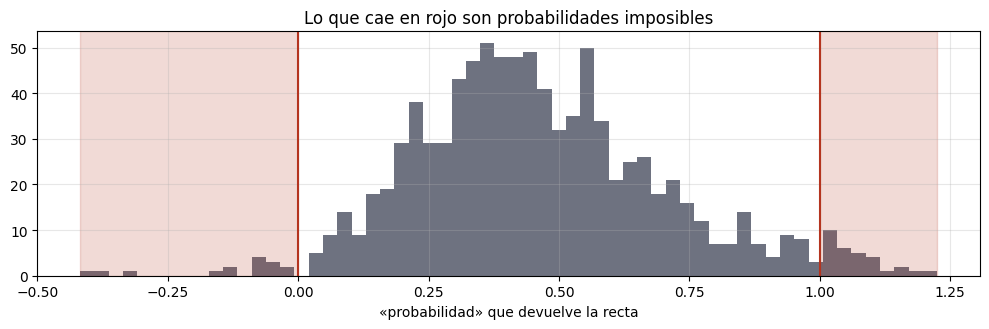

In [2]:
from sklearn.linear_model import LinearRegression

lineal = LinearRegression().fit(Xtr, ytr)
p_lineal = lineal.predict(Xte)

fuera = (p_lineal < 0) | (p_lineal > 1)
print(f"Predicción más baja : {p_lineal.min():+.3f}")
print(f"Predicción más alta : {p_lineal.max():+.3f}")
print(f"Fuera del rango 0-1 : {fuera.sum()} de {len(p_lineal)}  ({fuera.mean():.1%})")
print(f"   · por debajo de 0: {(p_lineal < 0).sum()}")
print(f"   · por encima de 1: {(p_lineal > 1).sum()}")

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.hist(p_lineal, bins=60, color=GRIS)
ax.axvspan(p_lineal.min(), 0, color=ROJO, alpha=.18)
ax.axvspan(1, p_lineal.max(), color=ROJO, alpha=.18)
ax.axvline(0, color=ROJO, lw=1.5); ax.axvline(1, color=ROJO, lw=1.5)
ax.set_xlabel("«probabilidad» que devuelve la recta")
ax.set_title("Lo que cae en rojo son probabilidades imposibles")
plt.tight_layout(); plt.show()

> **Cuarenta y cinco clientes recibieron una probabilidad imposible**: quince con
> probabilidad negativa de irse y treinta con más del 100 %.
>
> No es un error de programación. Es lo que pasa cuando se le pide a una recta que devuelva
> algo acotado entre 0 y 1: **la recta no sabe frenar**. Sigue de largo.

## A2 · La función logística

La idea es simple: calcular la misma suma de variables por coeficientes de siempre, y después
**aplastar** el resultado para que caiga entre 0 y 1.

La función que hace eso tiene forma de S: para valores muy negativos se pega al cero, para
valores muy positivos se pega al uno, y en el medio sube rápido. Nunca toca los extremos.

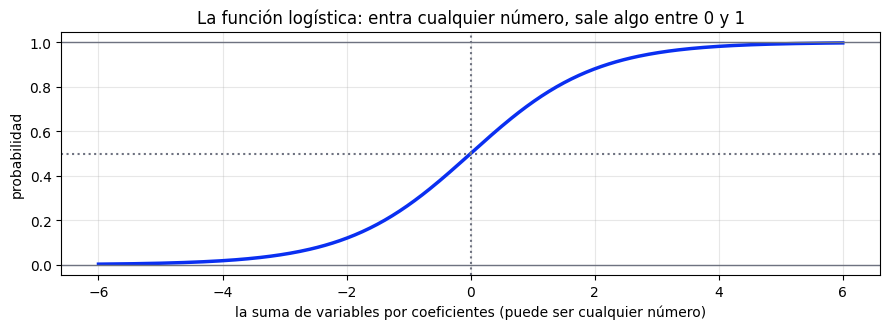

In [3]:
z = np.linspace(-6, 6, 300)
logistica = 1 / (1 + np.exp(-z))

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(z, logistica, color=AZUL, lw=2.5)
ax.axhline(0, color=GRIS, lw=1); ax.axhline(1, color=GRIS, lw=1)
ax.axhline(0.5, ls=":", color=GRIS); ax.axvline(0, ls=":", color=GRIS)
ax.set_xlabel("la suma de variables por coeficientes (puede ser cualquier número)")
ax.set_ylabel("probabilidad")
ax.set_title("La función logística: entra cualquier número, sale algo entre 0 y 1")
plt.tight_layout(); plt.show()

## A3 · El modelo

Son cuatro líneas, y el escalado ya lo conocen de la clase pasada —aunque acá cumple otra función, que explicamos abajo.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score

modelo = Pipeline([
    ("escalar", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000)),
]).fit(Xtr, ytr)

prob = modelo.predict_proba(Xte)[:, 1]   # la probabilidad  ← lo que vamos a usar
pred = modelo.predict(Xte)               # el veredicto con umbral 0,5 de fábrica

BASE = max(ytr.mean(), 1 - ytr.mean())
print(f"Línea de base : {BASE:.1%}")
print(f"Acierto       : {accuracy_score(yte, pred):.1%}")
print(f"AUC           : {roc_auc_score(yte, prob):.3f}")

Línea de base : 54.4%
Acierto       : 72.1%
AUC           : 0.772


> **Dos aclaraciones sobre el código.**
>
> `predict_proba` devuelve dos columnas: la probabilidad de quedarse y la de irse. El `[:, 1]`
> toma la segunda. `predict` devuelve directamente 0 o 1 aplicando un umbral de 0,5 **que
> nadie eligió**: viene de fábrica. Volvemos sobre esto al final.
>
> El **escalado acá no cambia las predicciones**, a diferencia de K-Means. Lo que cambia es la
> escala de los coeficientes: sin escalar, cada uno queda en su propia unidad y no se pueden
> comparar entre sí.

## A4 · Qué devuelve, cliente por cliente

El de menor riesgo, el más indeciso, y el de mayor riesgo:

            recencia  frecuencia        monto   prob  se_fue
id_cliente                                                  
1813               0          61  10681623.11  0.000       0
1001              81           3    279015.64  0.500       0
1835             378           1     75175.88  0.969       1


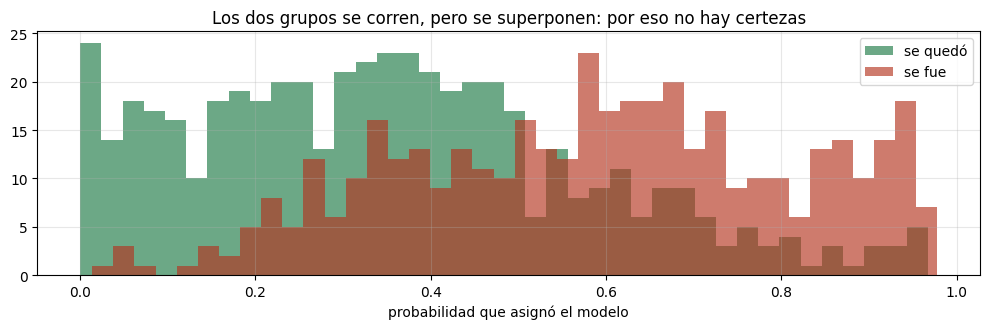

In [5]:
riesgo = Xte[["recencia", "frecuencia", "monto"]].copy()
riesgo["prob"] = prob.round(3)
riesgo["se_fue"] = yte.values
riesgo = riesgo.sort_values("prob")

medio = int((riesgo["prob"] - 0.5).abs().values.argmin())
print("El de menor riesgo, el más indeciso, y el de mayor riesgo:\n")
print(riesgo.iloc[[2, medio, -3]].to_string())

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.hist(prob[yte.values == 0], bins=40, alpha=.65, color=VERDE, label="se quedó")
ax.hist(prob[yte.values == 1], bins=40, alpha=.65, color=ROJO, label="se fue")
ax.set_xlabel("probabilidad que asignó el modelo"); ax.legend()
ax.set_title("Los dos grupos se corren, pero se superponen: por eso no hay certezas")
plt.tight_layout(); plt.show()

**El cliente del medio es el interesante.** El modelo le da 0,50, que es la forma honesta de
decir «no sé»: con la información disponible, ese cliente es una moneda al aire.

Y el gráfico muestra lo que ningún modelo de este tipo puede evitar: las dos distribuciones
**se superponen**. Hay clientes que se fueron con probabilidad baja y clientes que se
quedaron con probabilidad alta. El modelo no adivina; corre las probabilidades en la
dirección correcta.

## A5 · Los coeficientes

Acá es donde la logística le gana a casi cualquier otro modelo: se puede explicar.

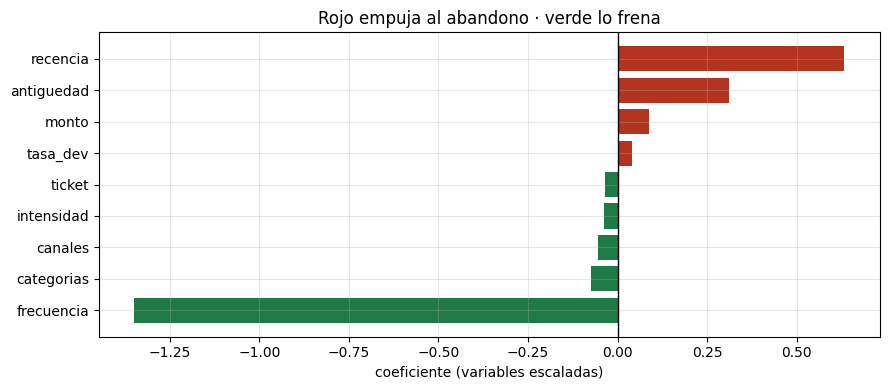

,coeficiente,multiplica las chances por,un desvío son
recencia,0.633,1.88,84
frecuencia,-1.348,0.26,7
antiguedad,0.310,1.36,113
monto,0.089,1.09,"1,425,756"
ticket,-0.036,0.96,"133,121"


In [6]:
coef = pd.Series(modelo["clf"].coef_[0], index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(coef.index, coef.values, color=[ROJO if v > 0 else VERDE for v in coef])
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("coeficiente (variables escaladas)")
ax.set_title("Rojo empuja al abandono · verde lo frena")
plt.tight_layout(); plt.show()

tabla = pd.DataFrame({
    "coeficiente": coef.round(3),
    "multiplica las chances por": np.exp(coef).round(2),
    "un desvío son": [f"{Xtr[v].std():,.0f}" for v in coef.index],
})
tabla.loc[["recencia", "frecuencia", "antiguedad", "monto", "ticket"]]

**Cómo se leen.** El signo dice la dirección y el tamaño dice cuánto. La columna del medio es
la más útil para explicárselo a alguien de negocio: son los **momios**, o sea por cuánto se
multiplican las chances de que el cliente se vaya cuando esa variable sube un desvío estándar.

- **Recencia, ×1,88.** Un desvío son 84 días. Pasar de 54 días sin comprar a 138 casi duplica
  las chances de irse.
- **Frecuencia, ×0,26.** Un desvío son 7 compras. Siete compras más bajan las chances al 26 %
  de lo que eran. Es, de lejos, el efecto más grande.
- **Ticket, ×0,96.** Prácticamente no distingue, igual que en el parcial 1.

> **Lo que un coeficiente NO dice.** No dice causa: que la recencia se asocie con el abandono
> no significa que esperar lo provoque. Las dos cosas son probablemente síntoma de lo mismo.
> Y no es un efecto aislado: recencia, frecuencia e intensidad están correlacionadas, así que
> cada coeficiente es «lo que esa variable aporta *además* de las otras».
>
> En el informe se escribe **«se asocia con»**, no «provoca».

## A6 · Contra qué se compara

La misma tabla de la clase 10, ahora con el modelo entendido.

In [7]:
regla = (Xte["recencia"] > 70).astype(int)

comparacion = pd.DataFrame([
    {"modelo": "Decir que no se va nadie",
     "acierto": accuracy_score(yte, np.zeros(len(yte))), "auc": 0.500},
    {"modelo": "Regla: recencia > 70 días",
     "acierto": accuracy_score(yte, regla), "auc": roc_auc_score(yte, Xte["recencia"])},
    {"modelo": "Logística, 9 variables",
     "acierto": accuracy_score(yte, pred), "auc": roc_auc_score(yte, prob)},
])
comparacion["sobre la base"] = (comparacion["acierto"] - comparacion["acierto"].iloc[0]) * 100
comparacion["acierto"] = (comparacion["acierto"] * 100).round(1)
comparacion.round(3)

,modelo,acierto,auc,sobre la base
0,Decir que no se va nadie,54.5,0.500,0.000
1,Regla: recencia > 70 días,69.6,0.754,15.109
2,"Logística, 9 variables",72.1,0.772,17.609


La ganancia del modelo sobre una regla de dos líneas es **chica**: 1,4 puntos de acierto.
Conviene decirlo sin vueltas.

Lo que el modelo sí agrega, y la regla no puede dar, es **una probabilidad por cliente**. Eso
es lo que permite ordenar a toda la base y después elegir dónde cortar según lo que cuesten
los errores.

In [8]:
print(f"De los 50 de mayor riesgo, se fueron: {riesgo.tail(50)['se_fue'].sum()} de 50")
print(f"De los 50 de menor riesgo, se fueron: {riesgo.head(50)['se_fue'].sum()} de 50")
print(f"Al azar, con {y.mean():.1%} de abandono, serían unos {50*y.mean():.0f}")

De los 50 de mayor riesgo, se fueron: 41 de 50
De los 50 de menor riesgo, se fueron: 4 de 50
Al azar, con 45.6% de abandono, serían unos 23


## A7 · ¿Se le puede creer al número?

Que el modelo ordene bien no garantiza que el **número** sea correcto. Un modelo puede decir
siempre «80 %» a gente que se va el 50 % de las veces y aun así ordenar perfecto: el AUC no lo
detecta, porque solo mira el orden.

Partimos a los clientes en diez grupos según la probabilidad que les dio el modelo y
comparamos lo que predijo contra lo que pasó.

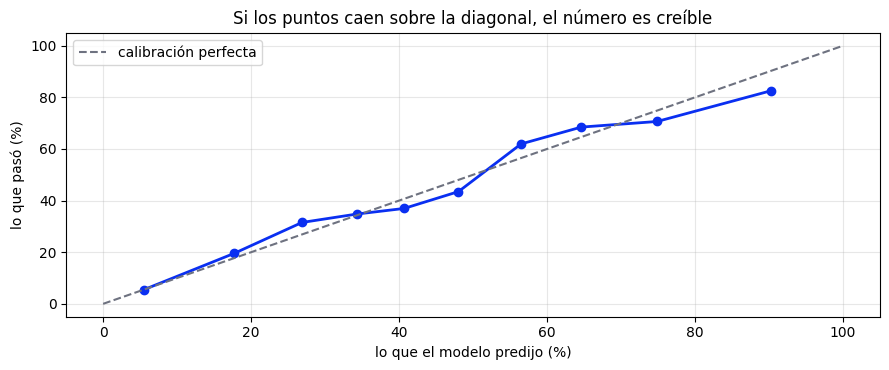

,clientes,predicho,real
decil,,,
1,92,5.5,5.4
2,92,17.7,19.6
3,92,26.9,31.5
4,92,34.3,34.8
5,92,40.7,37.0
6,92,48.0,43.5
7,92,56.5,62.0
8,92,64.6,68.5
9,92,74.9,70.7


In [9]:
cal = pd.DataFrame({"prob": prob, "real": yte.values})
cal["decil"] = pd.qcut(cal["prob"].rank(method="first"), 10, labels=range(1, 11))
tabla_cal = cal.groupby("decil", observed=True).agg(
    clientes=("prob", "size"),
    predicho=("prob", "mean"),
    real=("real", "mean"),
)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(tabla_cal["predicho"] * 100, tabla_cal["real"] * 100, "o-", color=AZUL, lw=2)
ax.plot([0, 100], [0, 100], ls="--", color=GRIS, label="calibración perfecta")
ax.set_xlabel("lo que el modelo predijo (%)"); ax.set_ylabel("lo que pasó (%)")
ax.legend(); ax.set_title("Si los puntos caen sobre la diagonal, el número es creíble")
plt.tight_layout(); plt.show()

(tabla_cal * [1, 100, 100]).round(1)

**Está bastante bien calibrado.** Cuando el modelo dice 27 %, se va alrededor del 30 %. Eso no
es automático y vale la pena verificarlo.

La excepción está arriba de todo: en el décimo de mayor riesgo el modelo dice 90 % y se va el
83 %. Está **confiado de más justo donde más importa**, que es donde se van a concentrar las
acciones de retención. Conviene anotarlo como limitación.

> **Por qué miramos esto hoy.** El 13/11, cuando calculemos cuánto conviene gastar en retener
> a un cliente, vamos a multiplicar la probabilidad por el valor del cliente. Si la
> probabilidad está inflada, toda esa cuenta da mal aunque el ranking sea impecable.

## A8 · El umbral

`predict` usó 0,5 por su cuenta. Veamos qué pasa si lo movemos.

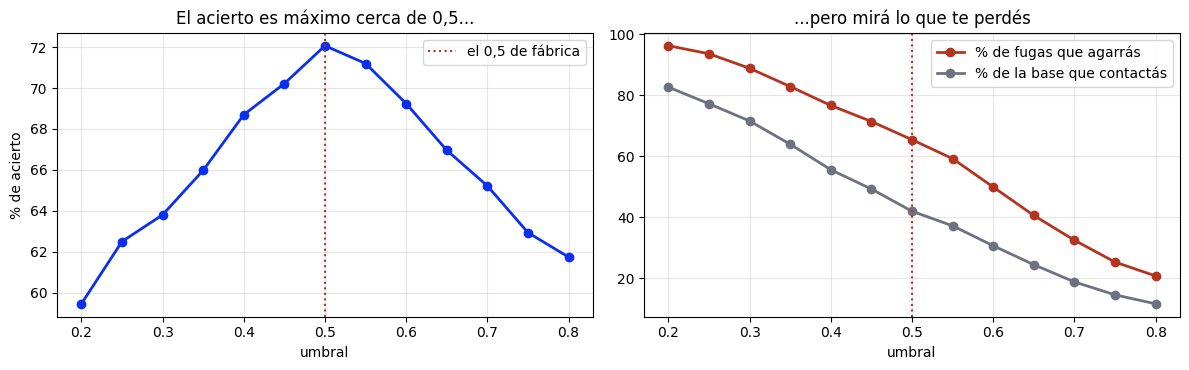

' umbral  acierto  llamás a  fugas que agarrás  % de las fugas\n    0.3    0.638       658                372           0.888\n    0.4    0.687       511                321           0.766\n    0.5    0.721       386                274           0.654\n    0.6    0.692       282                209           0.499\n    0.7    0.652       173                136           0.325'

In [10]:
filas = []
for u in np.arange(0.20, 0.85, 0.05):
    marca = (prob >= u).astype(int)
    filas.append({
        "umbral": round(u, 2),
        "acierto": accuracy_score(yte, marca),
        "llamás a": marca.sum(),
        "fugas que agarrás": int(((marca == 1) & (yte.values == 1)).sum()),
        "% de las fugas": ((marca == 1) & (yte.values == 1)).sum() / yte.sum(),
    })
umbrales = pd.DataFrame(filas)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
a1.plot(umbrales["umbral"], umbrales["acierto"] * 100, marker="o", color=AZUL, lw=2)
a1.axvline(0.5, ls=":", color=ROJO, label="el 0,5 de fábrica")
a1.set_xlabel("umbral"); a1.set_ylabel("% de acierto"); a1.legend()
a1.set_title("El acierto es máximo cerca de 0,5...")

a2.plot(umbrales["umbral"], umbrales["% de las fugas"] * 100, marker="o", color=ROJO,
        lw=2, label="% de fugas que agarrás")
a2.plot(umbrales["umbral"], umbrales["llamás a"] / len(yte) * 100, marker="o", color=GRIS,
        lw=2, label="% de la base que contactás")
a2.axvline(0.5, ls=":", color=ROJO); a2.set_xlabel("umbral"); a2.legend()
a2.set_title("...pero mirá lo que te perdés")
plt.tight_layout(); plt.show()

umbrales[umbrales["umbral"].isin([0.3, 0.4, 0.5, 0.6, 0.7])].round(3).to_string(index=False)

Con umbral **0,50** llamás a 386 clientes y agarrás 274 de las 419 fugas: el **65 %**.
Con umbral **0,30** llamás a 658 y agarrás 372: el **89 %**.

El acierto dice que 0,50 es mejor. Pero el acierto trata todos los errores como si costaran lo
mismo, y no cuestan lo mismo: llamar de más a alguien que se iba a quedar cuesta una llamada,
perder un cliente cuesta mucho más.

> **La pregunta que no se puede contestar con esta tabla:** ¿cuál de las dos filas conviene?
> Falta un dato que no está en el archivo — cuánto cuesta un contacto y cuánto vale un
> cliente. **Eso es la clase del 13/11**, y es la parte que cada equipo tiene que aplicar en el
> trabajo final con los valores del anexo de supuestos.

---
# Parte B · Su propio dataset

Sobre la tabla de clientes de la clase 8, la misma que usaron para segmentar.

In [ ]:
# B = pd.read_csv("mi_tabla_de_clientes.csv", index_col=0)
# yB = B.pop("churn")

B, yB = X.copy(), y.copy()      # ← reemplazar por SU tabla y SU etiqueta

print(f"Clientes : {len(B):,}")
print(f"Variables: {B.shape[1]}")
print(f"Abandono : {yB.mean():.1%}")
print(f"\nLínea de base: {max(yB.mean(), 1-yB.mean()):.1%}  ← el número a superar")

Clientes : 3,066
Variables: 9
Abandono : 45.6%

Línea de base: 54.4%  ← el número a superar


> **Si el abandono les da menos del 10 % o más del 90 %**, la ventana de resultado está mal
> elegida: casi todos caen de un lado y no hay nada que predecir. Vuelvan al corte antes de
> seguir.

In [ ]:
BtrX, BteX, Btry, Btey = train_test_split(B, yB, test_size=0.30,
                                          random_state=42, stratify=yB)

mB = Pipeline([("escalar", StandardScaler()),
               ("clf", LogisticRegression(max_iter=1000))]).fit(BtrX, Btry)
probB = mB.predict_proba(BteX)[:, 1]
predB = mB.predict(BteX)

baseB = max(Btry.mean(), 1 - Btry.mean())
print(f"Línea de base : {baseB:.1%}")
print(f"Acierto       : {accuracy_score(Btey, predB):.1%}   ({(accuracy_score(Btey, predB)-baseB)*100:+.1f} puntos)")
print(f"AUC           : {roc_auc_score(Btey, probB):.3f}")

if accuracy_score(Btey, predB) > 0.90:
    print("\n*** PARÁ. Más del 90 % de acierto casi siempre es fuga de información.")
    print("    Revisá si alguna variable se calculó con datos posteriores al corte.")

Línea de base : 54.4%
Acierto       : 72.1%   (+17.7 puntos)
AUC           : 0.772


## B2 · Los coeficientes de su modelo

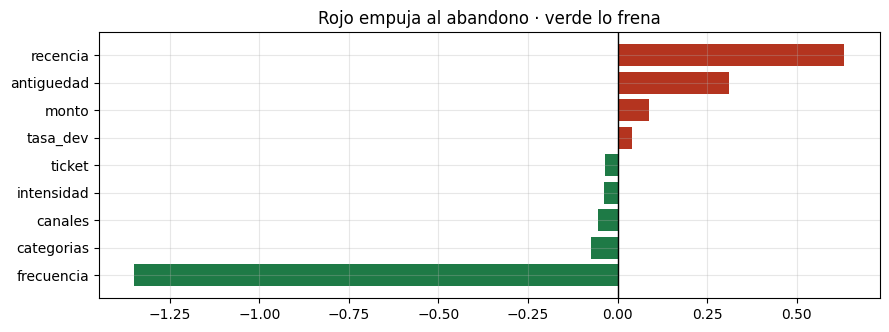

,coeficiente,multiplica las chances por
frecuencia,-1.348,0.26
categorias,-0.073,0.93
canales,-0.054,0.95
intensidad,-0.037,0.96
ticket,-0.036,0.96
tasa_dev,0.041,1.04
monto,0.089,1.09
antiguedad,0.310,1.36
recencia,0.633,1.88


In [ ]:
coefB = pd.Series(mB["clf"].coef_[0], index=B.columns).sort_values()

fig, ax = plt.subplots(figsize=(9, max(3, len(coefB) * 0.38)))
ax.barh(coefB.index, coefB.values, color=[ROJO if v > 0 else VERDE for v in coefB])
ax.axvline(0, color="k", lw=1)
ax.set_title("Rojo empuja al abandono · verde lo frena")
plt.tight_layout(); plt.show()

pd.DataFrame({"coeficiente": coefB.round(3),
              "multiplica las chances por": np.exp(coefB).round(2)})

**Escriban dos renglones**, en idioma de su negocio, contestando:

- ¿Qué variable protege más a un cliente?
- ¿Cuál lo empuja más hacia afuera?

Si alguna tiene el signo al revés de lo que esperaban, **eso es un hallazgo**: vale más en el
informe que diez variables con el signo esperado.

## B3 · El ranking

In [ ]:
rankB = pd.DataFrame({"prob": probB, "se_fue": Btey.values},
                     index=BteX.index).sort_values("prob", ascending=False)

n = max(20, len(rankB) // 10)
print(f"Del {n} de MAYOR riesgo, se fueron: {rankB.head(n)['se_fue'].sum()} ({rankB.head(n)['se_fue'].mean():.0%})")
print(f"Del {n} de MENOR riesgo, se fueron: {rankB.tail(n)['se_fue'].sum()} ({rankB.tail(n)['se_fue'].mean():.0%})")
print(f"Al azar serían unos {n * yB.mean():.0f} en cada grupo")

rankB.head(10).round(3)

Del 92 de MAYOR riesgo, se fueron: 76 (83%)
Del 92 de MENOR riesgo, se fueron: 5 (5%)
Al azar serían unos 42 en cada grupo


,prob,se_fue
id_cliente,,
2144,0.978,1
3174,0.971,1
1835,0.969,1
3818,0.967,0
862,0.965,1
1464,0.960,1
2344,0.958,1
3480,0.957,0
1423,0.957,1


### Lo que se guarda

```python
rankB.to_csv("mis_clientes_con_riesgo.csv")
```

Esa tabla —un cliente por fila, con su probabilidad— es lo que van a necesitar el 13/11 para
elegir el umbral, y es un entregable del trabajo final.

---
# Parcial 2 · viernes 13 de noviembre

| Clase | Tema | ¿Entra? |
|---|---|---|
| 10 · 16/10 | Línea de base, AUC, sobreajuste, train/test | **sí** |
| 11 · 23/10 | Segmentación con K-Means, escalado, elegir k | **sí** |
| 12 · 30/10 | Regresión logística, coeficientes, calibración, umbral | **sí** |
| 13 · 13/11 | Evaluación | no — se da ese día |

Mismo formato que el parcial 1: veinte preguntas de opción múltiple y cuatro de desarrollo
sobre el dataset de su equipo. **El 06/11 no hay clase**, así que son dos semanas.

### Para subir antes del 13/11

- La tabla de clientes con la probabilidad de abandono de cada uno.
- Las tres primeras partes de la sección de predicción del informe: la tabla de comparación
  contra la línea de base, los coeficientes leídos, y la calibración por deciles.